In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
train_df = pd.read_csv('/content/drive/MyDrive/file data/dataset svc/SVC_ Model/train.csv')
test_df = pd.read_csv('/content/drive/MyDrive/file data/dataset svc/SVC_ Model/test.csv')

In [3]:
train_df.head()
# Inspect the first few rows to understand data structure and feature types

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [4]:
train_df.tail()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
8688,9276_01,Europa,False,A/98/P,55 Cancri e,41.0,True,0.0,6819.0,0.0,1643.0,74.0,Gravior Noxnuther,False
8689,9278_01,Earth,True,G/1499/S,PSO J318.5-22,18.0,False,0.0,0.0,0.0,0.0,0.0,Kurta Mondalley,False
8690,9279_01,Earth,False,G/1500/S,TRAPPIST-1e,26.0,False,0.0,0.0,1872.0,1.0,0.0,Fayey Connon,True
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,353.0,3235.0,Celeon Hontichre,False
8692,9280_02,Europa,False,E/608/S,TRAPPIST-1e,44.0,False,126.0,4688.0,0.0,0.0,12.0,Propsh Hontichre,True


In [5]:
train_df.info()
# Check total entries, column data types, and non-null counts

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   object 
 1   HomePlanet    8492 non-null   object 
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   object 
 4   Destination   8511 non-null   object 
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   object 
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(7)
memory usage: 891.5+ KB


In [6]:
# total missing values
missing_values = train_df.isnull().sum()
print(missing_values)

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64


In [7]:
# Handling missing Bool values
bool_cols = ['CryoSleep', 'VIP']
for col in bool_cols:
  train_df[col] = train_df[col].fillna(train_df[col].mode()[0])

/tmp/ipykernel_148781/3005722709.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_df[col] = train_df[col].fillna(train_df[col].mode()[0])


In [8]:
# Handling missing categorical values
categorical_cols = ['HomePlanet', 'Destination']
for col in categorical_cols:
  train_df[col] = train_df[col].fillna(train_df[col].mode()[0])

In [9]:
# Handling missing values in Cabin
train_df[['Deck', 'Num', 'Side']] = train_df['Cabin'].str.split('/', expand= True)

for col in ['Deck', 'Side']:
  train_df[col] = train_df[col].fillna(train_df[col].mode()[0])

train_df['Num'] = pd.to_numeric(train_df['Num'], errors='coerce')
train_df['Num'] = train_df['Num'].fillna(train_df['Num'].median())

In [10]:
# Handling missing numerical values (Age)
train_df['Age'] = train_df['Age'].fillna(train_df['Age'].median())

In [11]:
# Handling missing numerical values (sleep)
expenditure_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
train_df.loc[train_df['CryoSleep'] == True, expenditure_cols] = train_df.loc[train_df['CryoSleep'] == True, expenditure_cols].fillna(0)

In [12]:
# Handling missing numerical values (Not sleep)
for col in expenditure_cols:
  train_df.loc[train_df['CryoSleep'] == False, col] = train_df.loc[train_df['CryoSleep'] == False, col].fillna(train_df[col].median())

In [13]:
# Drop (cabin, name)
train_df = train_df.drop(columns=['Cabin', 'Name', 'PassengerId'])

In [14]:
# total missing values after fillna and drop
train_df.isnull().sum()

,0
HomePlanet,0
CryoSleep,0
Destination,0
Age,0
VIP,0
RoomService,0
FoodCourt,0
ShoppingMall,0
Spa,0
VRDeck,0


In [15]:
# Check duplicated
train_df.duplicated().sum()

np.int64(25)

In [16]:
train_df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Num
count,8693.000000,8693.000000,8693.000000,8693.000000,8693.000000,8693.000000,8693.000000
mean,28.790291,220.009318,448.434027,169.572300,304.588865,298.261820,596.398942
std,14.341404,660.519050,1595.790627,598.007164,1125.562559,1134.126417,506.637799
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,173.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,427.000000
75%,37.000000,41.000000,61.000000,22.000000,53.000000,40.000000,983.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000,1894.000000


In [17]:
# The planets relationship with salvation
pd.crosstab(train_df['HomePlanet'], train_df['Transported'])

Transported,False,True
HomePlanet,,
Earth,2749,2054
Europa,727,1404
Mars,839,920


In [18]:
# The Destination relationship with salvation
pd.crosstab(train_df['Destination'], train_df['Transported'])

Transported,False,True
Destination,,
55 Cancri e,702,1098
PSO J318.5-22,395,401
TRAPPIST-1e,3218,2879


In [19]:
# The CryoSleep relationship with salvation
pd.crosstab(train_df['CryoSleep'], train_df['Transported'])

Transported,False,True
CryoSleep,,
False,3761,1895
True,554,2483


In [20]:
# The VIP relationship with salvation
pd.crosstab(train_df['VIP'], train_df['Transported'])

Transported,False,True
VIP,,
False,4192,4302
True,123,76


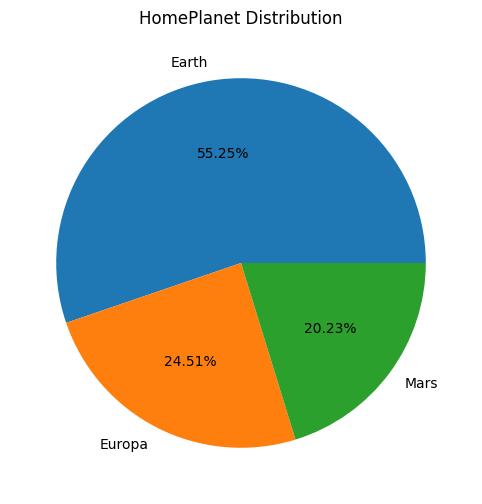

In [21]:
plt.figure(figsize=(10,6))
count_HomePlanet = train_df['HomePlanet'].value_counts()
plt.pie(count_HomePlanet, labels=count_HomePlanet.index, autopct='%.2f%%')
plt.title('HomePlanet Distribution')
plt.show()

Insight: More than half of the passengers (55.25%) originated from Earth, followed by Europa (24.51%) and Mars (20.23%).

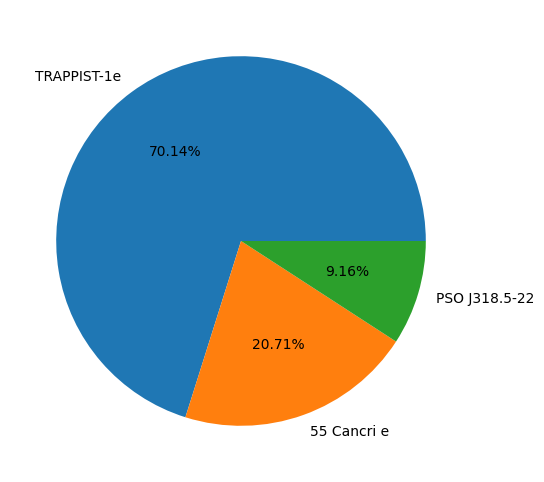

In [22]:
plt.figure(figsize=(10,6))
count_Destination = train_df['Destination'].value_counts()
plt.pie(count_Destination, labels=count_Destination.index, autopct='%.2f%%')
plt.show()

Insight: TRAPPIST-1e is the primary destination for the vast majority of passengers (70.14%), followed by 55 Cancri e (20.71%) and PSO J318.5-22 (9.16%).

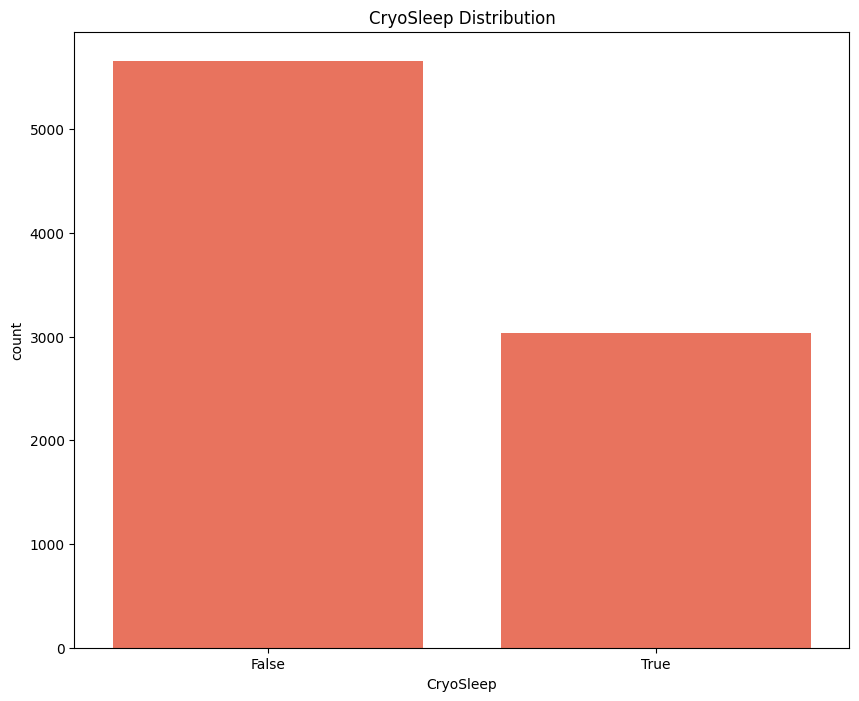

In [23]:
plt.figure(figsize=(10,8));
sns.countplot(x= train_df['CryoSleep'], color= 'tomato');
plt.title('CryoSleep Distribution');
plt.show;

Observation: Most passengers chose not to enter CryoSleep (False), outnumbering those who were in CryoSleep (True) by a significant margin.

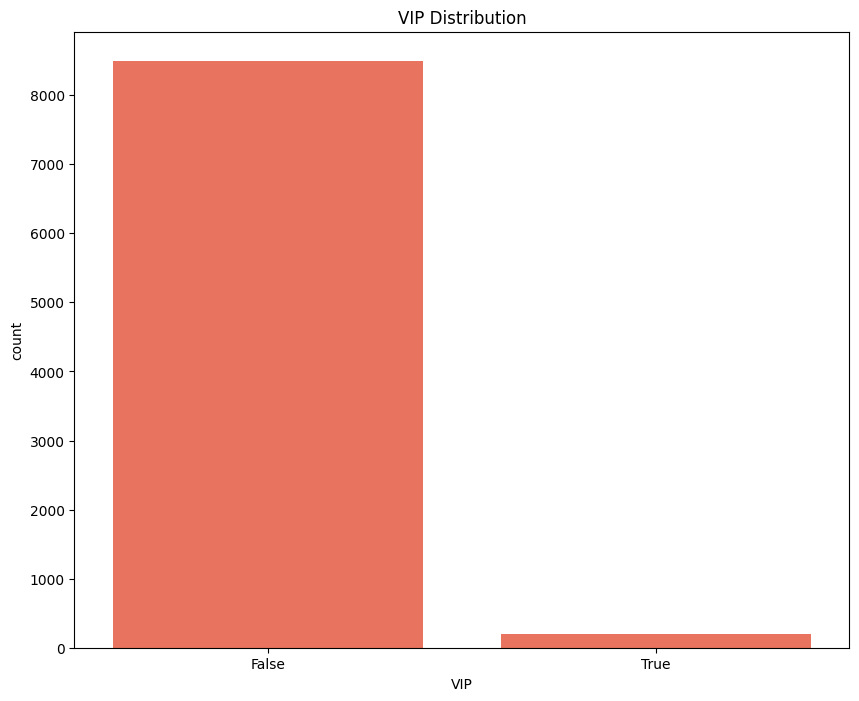

In [24]:
plt.figure(figsize=(10,8));
sns.countplot(x = train_df['VIP'], color= 'tomato');
plt.title('VIP Distribution');
plt.show;

Insight: The vast majority of passengers are non-VIPs (False), with VIP passengers (True) making up only a tiny fraction of the total dataset.

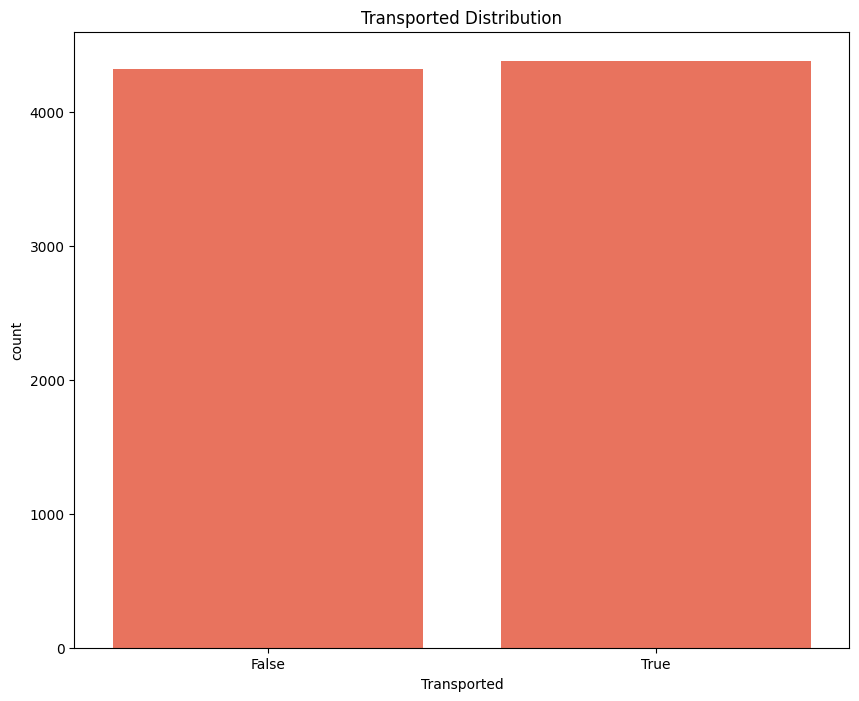

In [25]:
plt.figure(figsize=(10,8));
sns.countplot(x = train_df['Transported'], color= 'tomato');
plt.title('Transported Distribution');
plt.show;

Insight: The target variable Transported is well-balanced, with almost an equal split between passengers who were transported (True) and those who were not (False).

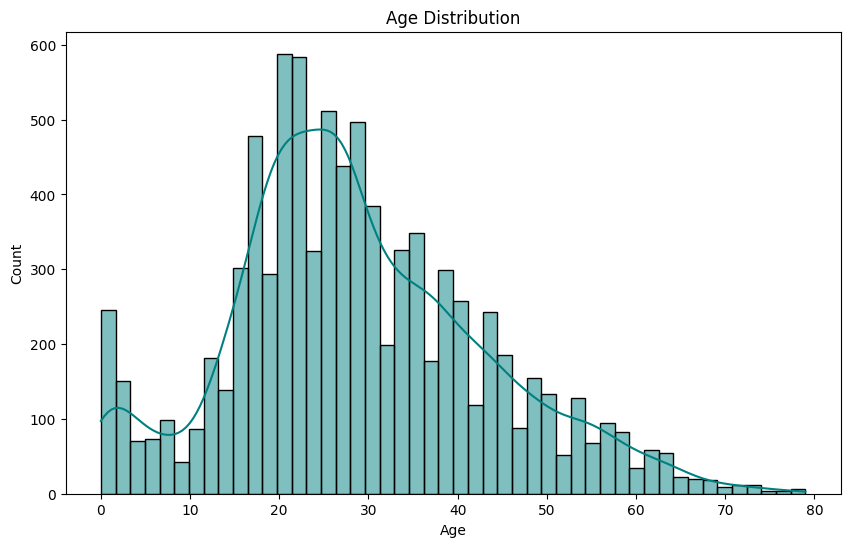

In [26]:
plt.figure(figsize=(10,6));
sns.histplot(x = train_df['Age'], kde= True, color= 'teal');
plt.title('Age Distribution');
plt.show;

Note: The age distribution shows a peak around 18–30 years, indicating that young adults make up the majority of the passengers.

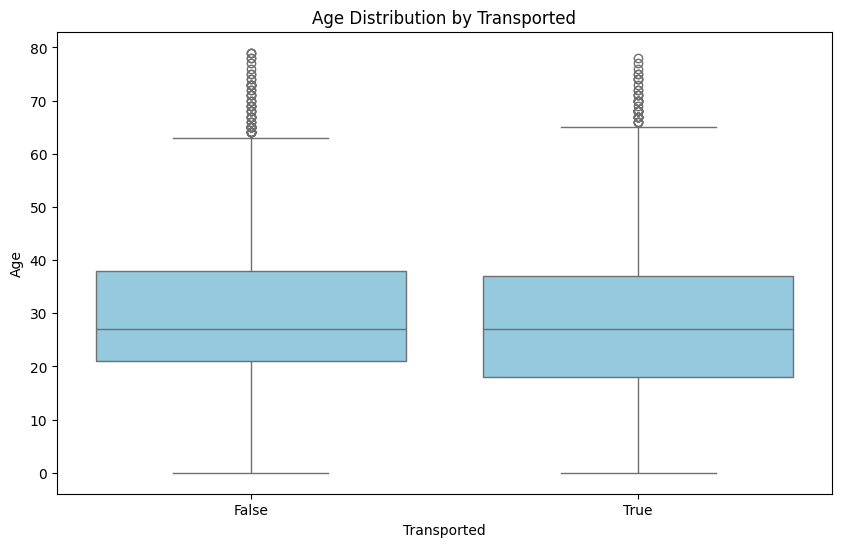

In [27]:
plt.figure(figsize=(10,6));
sns.boxplot(x=train_df['Transported'], y=train_df['Age'], color = 'skyblue');
plt.xlabel('Transported');
plt.ylabel('Age');
plt.title('Age Distribution by Transported');

Insight: The age distribution is very similar for both transported (True) and non-transported (False) passengers, with a median age around 27 years for both groups.

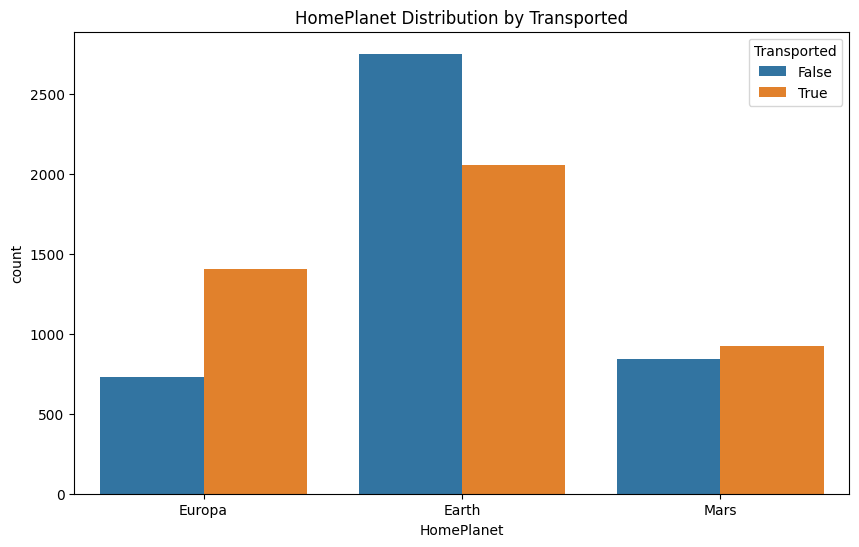

In [28]:
plt.figure(figsize=(10,6))
sns.countplot(x= train_df['HomePlanet'], hue= train_df['Transported'])
plt.title('HomePlanet Distribution by Transported');
plt.show;

Insight: Passengers from Europa were significantly more likely to be transported (True), while the majority of passengers from Earth were not transported (False). Passengers from Mars were roughly evenly split.

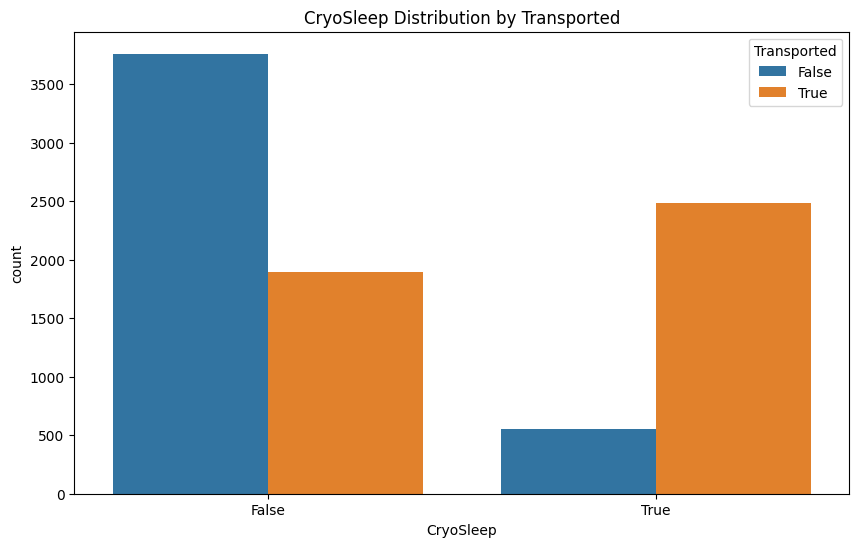

In [29]:
plt.figure(figsize=(10,6))
sns.countplot(x= train_df['CryoSleep'], hue= train_df['Transported'])
plt.title('CryoSleep Distribution by Transported');
plt.show;

Insight: Passengers in CryoSleep (True) were overwhelmingly more likely to be transported, making CryoSleep the strongest predictor in the dataset.

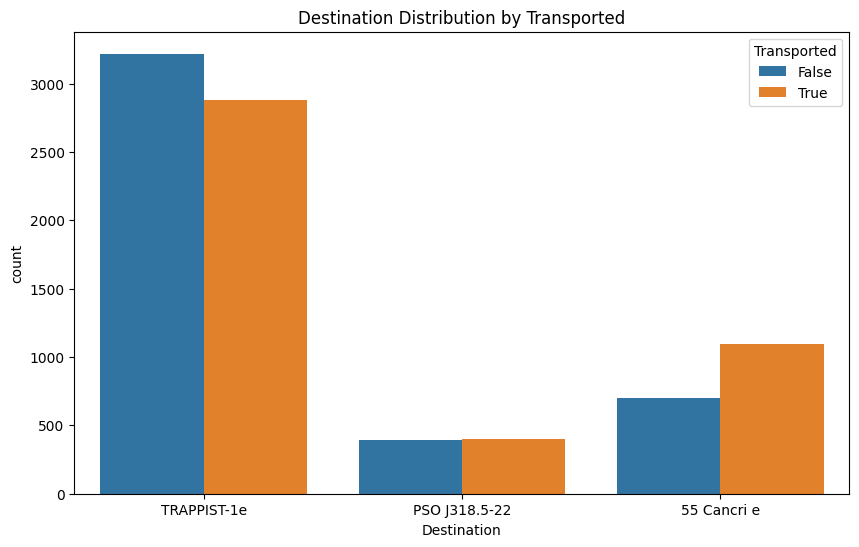

In [30]:
plt.figure(figsize=(10,6))
sns.countplot(x= train_df['Destination'], hue= train_df['Transported'])
plt.title('Destination Distribution by Transported');
plt.show;

Insight: Passengers traveling to 55 Cancri e had a higher likelihood of being transported (True), while the majority heading to TRAPPIST-1e were not transported (False). PSO J318.5-22 shows an almost equal split.

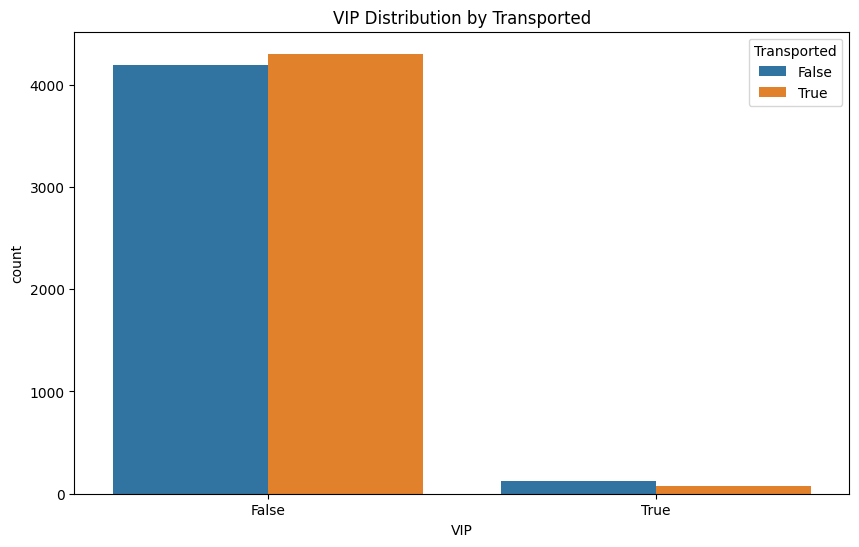

In [31]:
plt.figure(figsize=(10,6))
sns.countplot(x= train_df['VIP'], hue= train_df['Transported'])
plt.title('VIP Distribution by Transported');
plt.show;

Insight: VIP status shows little impact on transportation, as non-VIPs (False) are split evenly and VIPs (True) represent a very small portion of the dataset.

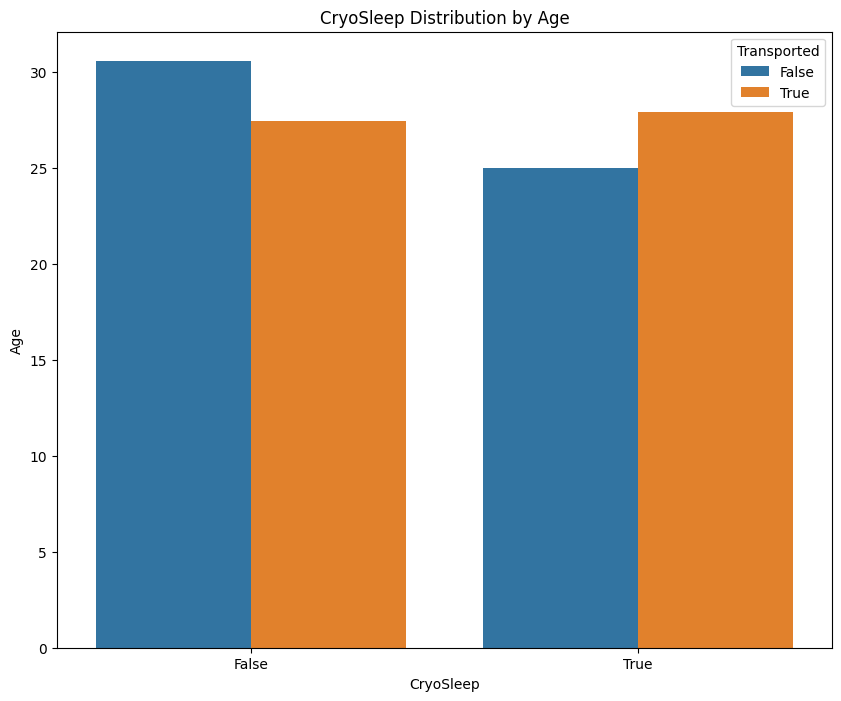

In [32]:
plt.figure(figsize=(10,8));
sns.barplot(x= train_df['CryoSleep'], y= train_df['Age'], hue= train_df['Transported'], errorbar= None);
plt.title('CryoSleep Distribution by Age');
plt.show;

Insight: Average age remains fairly stable around 25–30 across both CryoSleep statuses, showing that age doesn't significantly alter CryoSleep trends for transported passengers.

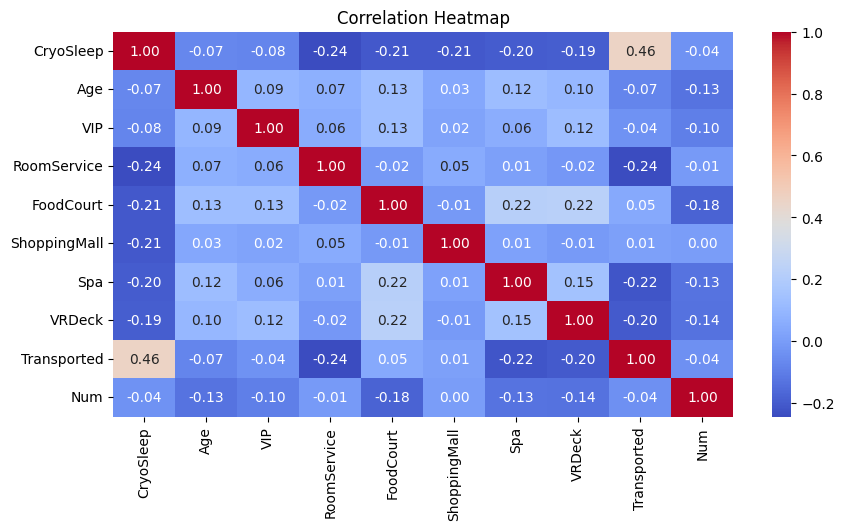

In [33]:
plt.figure(figsize=(10,5));
sns.heatmap(train_df.corr(numeric_only= True), annot= True, cmap= 'coolwarm', fmt= ".2f");
plt.title('Correlation Heatmap');
plt.show;

Observation: The heatmap confirms that CryoSleep is the most strongly correlated feature with the target variable Transported (0.46).

In [34]:
test_df.head()
# Inspect the first few rows to understand data structure and feature types

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
0,0013_01,Earth,True,G/3/S,TRAPPIST-1e,27.0,False,0.0,0.0,0.0,0.0,0.0,Nelly Carsoning
1,0018_01,Earth,False,F/4/S,TRAPPIST-1e,19.0,False,0.0,9.0,0.0,2823.0,0.0,Lerome Peckers
2,0019_01,Europa,True,C/0/S,55 Cancri e,31.0,False,0.0,0.0,0.0,0.0,0.0,Sabih Unhearfus
3,0021_01,Europa,False,C/1/S,TRAPPIST-1e,38.0,False,0.0,6652.0,0.0,181.0,585.0,Meratz Caltilter
4,0023_01,Earth,False,F/5/S,TRAPPIST-1e,20.0,False,10.0,0.0,635.0,0.0,0.0,Brence Harperez


In [35]:
test_df.tail()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name
4272,9266_02,Earth,True,G/1496/S,TRAPPIST-1e,34.0,False,0.0,0.0,0.0,0.0,0.0,Jeron Peter
4273,9269_01,Earth,False,NaN,TRAPPIST-1e,42.0,False,0.0,847.0,17.0,10.0,144.0,Matty Scheron
4274,9271_01,Mars,True,D/296/P,55 Cancri e,NaN,False,0.0,0.0,0.0,0.0,0.0,Jayrin Pore
4275,9273_01,Europa,False,D/297/P,NaN,NaN,False,0.0,2680.0,0.0,0.0,523.0,Kitakan Conale
4276,9277_01,Earth,True,G/1498/S,PSO J318.5-22,43.0,False,0.0,0.0,0.0,0.0,0.0,Lilace Leonzaley


In [36]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4277 entries, 0 to 4276
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   4277 non-null   object 
 1   HomePlanet    4190 non-null   object 
 2   CryoSleep     4184 non-null   object 
 3   Cabin         4177 non-null   object 
 4   Destination   4185 non-null   object 
 5   Age           4186 non-null   float64
 6   VIP           4184 non-null   object 
 7   RoomService   4195 non-null   float64
 8   FoodCourt     4171 non-null   float64
 9   ShoppingMall  4179 non-null   float64
 10  Spa           4176 non-null   float64
 11  VRDeck        4197 non-null   float64
 12  Name          4183 non-null   object 
dtypes: float64(6), object(7)
memory usage: 434.5+ KB


In [37]:
# total missing values
missing_values_test = test_df.isnull().sum()
print(missing_values_test)

PassengerId       0
HomePlanet       87
CryoSleep        93
Cabin           100
Destination      92
Age              91
VIP              93
RoomService      82
FoodCourt       106
ShoppingMall     98
Spa             101
VRDeck           80
Name             94
dtype: int64


In [38]:
# Handling missing Bool values
bool_cols_test = ['CryoSleep', 'VIP']
for col in bool_cols_test:
  test_df[col] = test_df[col].fillna(test_df[col].mode()[0])

/tmp/ipykernel_148781/4138213138.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_df[col] = test_df[col].fillna(test_df[col].mode()[0])


In [39]:
# Handling missing categorical values
categorical_cols_test = ['HomePlanet', 'Destination']
for col in categorical_cols_test:
  test_df[col] = test_df[col].fillna(test_df[col].mode()[0])

In [40]:
# Handling missing values in Cabin
test_df[['Deck', 'Num', 'Side']] = test_df['Cabin'].str.split('/', expand= True)

for col in ['Deck', 'Side']:
  test_df[col] = test_df[col].fillna(test_df[col].mode()[0])

test_df['Num'] = pd.to_numeric(test_df['Num'], errors='coerce')
test_df['Num'] = test_df['Num'].fillna(test_df['Num'].median())

In [41]:
# Handling missing numerical values (Age)
test_df['Age'] = test_df['Age'].fillna(test_df['Age'].median())

In [42]:
# Handling missing numerical values (sleep)
expenditure_cols_test = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
test_df.loc[test_df['CryoSleep'] == True, expenditure_cols_test] = test_df.loc[test_df['CryoSleep'] == True, expenditure_cols_test].fillna(0)

In [43]:
# Handling missing numerical values (Not sleep)
for col in expenditure_cols_test:
  test_df.loc[test_df['CryoSleep'] == False, col] = test_df.loc[test_df['CryoSleep'] == False, col].fillna(test_df[col].median())

In [44]:
# Drop (cabin, name)
test_df = test_df.drop(columns=['Cabin', 'Name', 'PassengerId'])

In [45]:
# total missing values after fillna and drop
test_df.isnull().sum()

,0
HomePlanet,0
CryoSleep,0
Destination,0
Age,0
VIP,0
RoomService,0
FoodCourt,0
ShoppingMall,0
Spa,0
VRDeck,0


In [46]:
# Check duplicated
test_df.duplicated().sum()

np.int64(13)

In [47]:
test_df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Num
count,4277.000000,4277.000000,4277.000000,4277.000000,4277.000000,4277.000000,4277.000000
mean,28.601590,215.062427,428.592238,173.233107,295.895955,304.898293,606.246668
std,14.032629,601.914503,1510.155974,554.991776,1104.872018,1235.991811,509.545187
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,179.000000
50%,26.000000,0.000000,0.000000,0.000000,0.000000,0.000000,442.000000
75%,37.000000,48.000000,66.000000,27.000000,43.000000,31.000000,1012.000000
max,79.000000,11567.000000,25273.000000,8292.000000,19844.000000,22272.000000,1890.000000


In [48]:
# Save the train set length to split the datasets later
train_df_len = len(train_df)
# Concatenate train and test sets to maintain column consistency
combined_df = pd.concat([train_df, test_df], axis= 0, ignore_index= True)
# Define categorical features for encoding
categ_cols = ['HomePlanet', 'CryoSleep', 'Destination', 'VIP', 'Deck', 'Side']
# Perform unified One-Hot Encoding
combined_encoded = pd.get_dummies(combined_df, columns= categ_cols, drop_first= True)
# Split back into train and test sets using the saved length
train_df_encoded = combined_encoded[:train_df_len]
test_df_encoded = combined_encoded[train_df_len:]
# Remove target column from test set
test_df_encoded = test_df_encoded.drop('Transported', axis= 1)

In [49]:
train_df_encoded.head()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Num,HomePlanet_Europa,HomePlanet_Mars,...,Destination_TRAPPIST-1e,VIP_True,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_S
0,39.0,0.0,0.0,0.0,0.0,0.0,False,0.0,True,False,...,True,False,True,False,False,False,False,False,False,False
1,24.0,109.0,9.0,25.0,549.0,44.0,True,0.0,False,False,...,True,False,False,False,False,False,True,False,False,True
2,58.0,43.0,3576.0,0.0,6715.0,49.0,False,0.0,True,False,...,True,True,False,False,False,False,False,False,False,True
3,33.0,0.0,1283.0,371.0,3329.0,193.0,False,0.0,True,False,...,True,False,False,False,False,False,False,False,False,True
4,16.0,303.0,70.0,151.0,565.0,2.0,True,1.0,False,False,...,True,False,False,False,False,False,True,False,False,True


In [50]:
train_df_encoded.tail()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Transported,Num,HomePlanet_Europa,HomePlanet_Mars,...,Destination_TRAPPIST-1e,VIP_True,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_S
8688,41.0,0.0,6819.0,0.0,1643.0,74.0,False,98.0,True,False,...,False,True,False,False,False,False,False,False,False,False
8689,18.0,0.0,0.0,0.0,0.0,0.0,False,1499.0,False,False,...,False,False,False,False,False,False,False,True,False,True
8690,26.0,0.0,0.0,1872.0,1.0,0.0,True,1500.0,False,False,...,True,False,False,False,False,False,False,True,False,True
8691,32.0,0.0,1049.0,0.0,353.0,3235.0,False,608.0,True,False,...,False,False,False,False,False,True,False,False,False,True
8692,44.0,126.0,4688.0,0.0,0.0,12.0,True,608.0,True,False,...,True,False,False,False,False,True,False,False,False,True


In [51]:
test_df_encoded.head()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Num,HomePlanet_Europa,HomePlanet_Mars,CryoSleep_True,...,Destination_TRAPPIST-1e,VIP_True,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_S
8693,27.0,0.0,0.0,0.0,0.0,0.0,3.0,False,False,True,...,True,False,False,False,False,False,False,True,False,True
8694,19.0,0.0,9.0,0.0,2823.0,0.0,4.0,False,False,False,...,True,False,False,False,False,False,True,False,False,True
8695,31.0,0.0,0.0,0.0,0.0,0.0,0.0,True,False,True,...,False,False,False,True,False,False,False,False,False,True
8696,38.0,0.0,6652.0,0.0,181.0,585.0,1.0,True,False,False,...,True,False,False,True,False,False,False,False,False,True
8697,20.0,10.0,0.0,635.0,0.0,0.0,5.0,False,False,False,...,True,False,False,False,False,False,True,False,False,True


In [52]:
test_df_encoded.tail()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Num,HomePlanet_Europa,HomePlanet_Mars,CryoSleep_True,...,Destination_TRAPPIST-1e,VIP_True,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_S
12965,34.0,0.0,0.0,0.0,0.0,0.0,1496.0,False,False,True,...,True,False,False,False,False,False,False,True,False,True
12966,42.0,0.0,847.0,17.0,10.0,144.0,442.0,False,False,False,...,True,False,False,False,False,False,True,False,False,True
12967,26.0,0.0,0.0,0.0,0.0,0.0,296.0,False,True,True,...,False,False,False,False,True,False,False,False,False,False
12968,26.0,0.0,2680.0,0.0,0.0,523.0,297.0,True,False,False,...,True,False,False,False,True,False,False,False,False,False
12969,43.0,0.0,0.0,0.0,0.0,0.0,1498.0,False,False,True,...,False,False,False,False,False,False,False,True,False,True


In [53]:
expenditure_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']

train_df_encoded['TotalSpent'] = train_df_encoded[expenditure_cols].sum(axis=1)
test_df_encoded['TotalSpent'] = test_df_encoded[expenditure_cols].sum(axis=1)

train_df_encoded['IsZeroSpent'] = (train_df_encoded['TotalSpent'] == 0).astype(int)
test_df_encoded['IsZeroSpent'] = (test_df_encoded['TotalSpent'] == 0).astype(int)

/tmp/ipykernel_148781/3584514057.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df_encoded['TotalSpent'] = train_df_encoded[expenditure_cols].sum(axis=1)
/tmp/ipykernel_148781/3584514057.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df_encoded['IsZeroSpent'] = (train_df_encoded['TotalSpent'] == 0).astype(int)


In [54]:
x_train = train_df_encoded.drop('Transported', axis= 1)
y_train = train_df_encoded['Transported'].astype(int)

In [55]:
x_test = test_df_encoded.copy()

In [56]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [57]:
model = SVC(kernel='rbf', C=1.0)
model.fit(x_train_scaled, y_train)

SVC()

In [58]:
y_pred = model.predict(x_test_scaled)

In [59]:
print("Train Accuracy :", model.score(x_train_scaled, y_train) * 100)

Train Accuracy : 81.28379155642472


In [60]:
classification_report = classification_report(y_train, model.predict(x_train_scaled))
print("Classification Report:\n", classification_report)

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.81      0.81      4315
           1       0.81      0.81      0.81      4378

    accuracy                           0.81      8693
   macro avg       0.81      0.81      0.81      8693
weighted avg       0.81      0.81      0.81      8693



In [61]:
print("Confusion Matrix:\n", confusion_matrix(y_train, model.predict(x_train_scaled)))

Confusion Matrix:
 [[3507  808]
 [ 819 3559]]


In [62]:
y_pred_bool = y_pred.astype(bool)

In [63]:
test_original = pd.read_csv('/content/drive/MyDrive/file data/dataset svc/SVC_ Model/test.csv')

In [64]:
submission = pd.DataFrame({
    'PassengerId': test_original['PassengerId'],
    'Transported': y_pred_bool
})

In [65]:
submission.to_csv('submission.csv', index=False)

In [66]:
submission.head()

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,False
